# Exploratory Data Analysis of Brazilian E-Commerce Orders
**Course:** CSB314 — Exploratory Data Analysis  
**Assessment:** Minor Project 02 / CA 03  
**Dataset:** Brazilian E-Commerce Public Dataset by Olist (Kaggle)

## Project question
What do the Olist order, item, customer, payment and review records show about sales value, delivery performance and customer ratings?

## Dataset Details
**Dataset Source:** Kaggle  
**Dataset Name:**  Brazilian E-Commerce Public Dataset by Olist.  
**Dataset URL:** https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce.  

## 1. Analytical Objectives

The analysis focuses on:
- how order value and freight vary across product categories and time.
- how long orders take to reach customers and how that compares with the estimated delivery date.
- how review scores vary across order and delivery characteristics;
- whether numerical variables move together, and how extreme observations affect summaries.


## 2. Dataset Source and Description
The selected dataset(**Brazilian E-Commerce Dataset by Olist**) contains anonymised marketplace records from 2016–2018.

| CSV file | Important keys |
|---|---|
| `olist_orders_dataset.csv` | `order_id`, `customer_id` |
| `olist_customers_dataset.csv` | `customer_id` |
| `olist_order_items_dataset.csv` | `order_id`, `product_id`, `seller_id` |
| `olist_order_payments_dataset.csv` | `order_id` |
| `olist_order_reviews_dataset.csv` | `order_id` |
| `olist_products_dataset.csv` | `product_id` |
| `olist_sellers_dataset.csv` | `seller_id` |
| `product_category_name_translation.csv` | `product_category_name` |

The main analysis uses the orders, customers, items, payments, reviews, products and category translation in the dataset.

## 3. Importing Libraries and Loading Data
**Objective:** Load the required tables and retain untouched raw copies.  
**Concept and method:** Pandas handles tabular data, NumPy supports numerical calculations, Matplotlib and Seaborn create visualisations.

In [1]:
# Import the libraries used throughout the analysis.
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Keep plots readable and use a consistent visual style.
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

# Fix the random seed so sampling demonstrations can be reproduced.
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Set the relative folder containing the Kaggle CSV files.
DATA_DIR = Path("data/olist") if Path("data/olist").exists() else Path(".")

# List the CSV files required for this analysis.
file_names = {
    "orders": "olist_orders_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "products": "olist_products_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
    "sellers": "olist_sellers_dataset.csv",
}

# Helper to find file either in current directory or DATA_DIR
def get_file_path(fname):
    if Path(fname).exists():
        return Path(fname)
    elif (DATA_DIR / fname).exists():
        return DATA_DIR / fname
    return Path(fname)

# Read each CSV into an untouched raw DataFrame.
raw = {
    name: pd.read_csv(get_file_path(file_name))
    for name, file_name in file_names.items()
}

# Create clearly named working copies for analysis.
orders = raw["orders"].copy()
customers = raw["customers"].copy()
items = raw["items"].copy()
payments = raw["payments"].copy()
reviews = raw["reviews"].copy()
products = raw["products"].copy()
category_translation = raw["category_translation"].copy()
sellers = raw["sellers"].copy()

# Show the loaded row counts so the source files can be checked.
pd.DataFrame({
    "table": list(raw.keys()),
    "rows": [len(frame) for frame in raw.values()],
    "columns": [len(frame.columns) for frame in raw.values()]
})


,table,rows,columns
0,orders,99441,8
1,customers,99441,5
2,items,112650,7
3,payments,103886,5
4,reviews,99224,7
5,products,32951,9
6,category_translation,71,2
7,sellers,3095,4


**Output and interpretation:** The table above reports the actual number of rows and columns read from each local CSV.

## 4. Dataset Understanding
**Objective:** Understand table dimensions, data types, sample records and grain of each table before joining.  
**Concept:** The grain describes what one row represents and It is essential because one-to-many relationship can increase number of rows after a merge

In [2]:
# Display the first five order records.
display(orders.head())

# Display the structure and non-null counts of the main order table.
orders.info()

# Summarise the grain and key columns of each selected table.
grain_summary = pd.DataFrame({
    "table": ["orders", "customers", "items", "payments", "reviews", "products"],
    "one_row_represents": [
        "one order", "one customer record", "one order item",
        "one payment record", "one review record", "one product"
    ],
    "candidate_key": [
        "order_id", "customer_id", "order_id + order_item_id",
        "order_id + payment_sequential", "review_id", "product_id"
    ]
})
display(grain_summary)

# Display numerical and categorical summaries of the order table.
display(orders.describe(include="all").T)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


,table,one_row_represents,candidate_key
0,orders,one order,order_id
1,customers,one customer record,customer_id
2,items,one order item,order_id + order_item_id
3,payments,one payment record,order_id + payment_sequential
4,reviews,one review record,review_id
5,products,one product,product_id


,count,unique,top,freq
order_id,99441,99441,66dea50a8b16d9b4dee7af250b4be1a5,1
customer_id,99441,99441,edb027a75a1449115f6b43211ae02a24,1
order_status,99441,8,delivered,96478
order_purchase_timestamp,99441,98875,2018-08-02 12:05:26,3
order_approved_at,99281,90733,2018-02-27 04:31:10,9
order_delivered_carrier_date,97658,81018,2018-05-09 15:48:00,47
order_delivered_customer_date,96476,95664,2018-05-08 19:36:48,3
order_estimated_delivery_date,99441,459,2017-12-20 00:00:00,522


**Interpretation and observation:** Use the displayed sample, schema and summaries to verify the actual column names, types and table grain. The item, payment and review tables must not be assumed to have one row per order.

## 5. Data Quality — Initial Checks
**Objective:** Check completeness, duplicates, data types, category consistency, plausibility and key integrity before engineering features.  
**Method:** Missing counts and percentages are calculated column-wise. Exact duplicates and key duplicates are counted separately because repeated child-table keys may be valid. Date parsing failures and invalid numerical values are checked explicitly.

In [3]:
# Calculate missing-value counts and percentages for every selected table.
missing_report = []
for table_name, frame in raw.items():
    for column in frame.columns:
        missing_count = frame[column].isna().sum()
        missing_report.append({
            "table": table_name,
            "column": column,
            "missing_count": int(missing_count),
            "missing_percent": 100 * missing_count / len(frame) if len(frame) else np.nan
        })
missing_report = pd.DataFrame(missing_report)
display(missing_report.query("missing_count > 0").sort_values(
    ["table", "missing_count"], ascending=[True, False]
))

# Count exact duplicate rows in each raw table.
duplicate_report = pd.DataFrame({
    "table": list(raw.keys()),
    "exact_duplicate_rows": [int(frame.duplicated().sum()) for frame in raw.values()]
})
display(duplicate_report)

# Check candidate-key uniqueness at the grain of each table.
key_checks = pd.DataFrame({
    "table": ["orders", "customers", "items", "payments", "reviews", "products"],
    "key": ["order_id", "customer_id", "order_id + order_item_id",
            "order_id + payment_sequential", "review_id", "product_id"],
    "duplicate_key_rows": [
        int(orders.duplicated(["order_id"]).sum()),
        int(customers.duplicated(["customer_id"]).sum()),
        int(items.duplicated(["order_id", "order_item_id"]).sum()),
        int(payments.duplicated(["order_id", "payment_sequential"]).sum()),
        int(reviews.duplicated(["review_id"]).sum()),
        int(products.duplicated(["product_id"]).sum())
    ]
})
display(key_checks)

# Inspect data types and category labels in important columns.
display(orders.dtypes.rename("data_type").to_frame())
display(orders["order_status"].value_counts(dropna=False).to_frame("count"))
display(customers["customer_state"].value_counts(dropna=False).head(10).to_frame("count"))

# Check whether item prices or freight values are negative or zero.
display(pd.DataFrame({
    "check": ["negative price", "zero price", "negative freight", "zero freight"],
    "count": [
        int((items["price"] < 0).sum()),
        int((items["price"] == 0).sum()),
        int((items["freight_value"] < 0).sum()),
        int((items["freight_value"] == 0).sum())
    ]
}))

,table,column,missing_count,missing_percent
6,orders,order_delivered_customer_date,2965,2.98
5,orders,order_delivered_carrier_date,1783,1.79
4,orders,order_approved_at,160,0.16
33,products,product_category_name,610,1.85
34,products,product_name_lenght,610,1.85
35,products,product_description_lenght,610,1.85
36,products,product_photos_qty,610,1.85
37,products,product_weight_g,2,0.01
38,products,product_length_cm,2,0.01
39,products,product_height_cm,2,0.01


,table,exact_duplicate_rows
0,orders,0
1,customers,0
2,items,0
3,payments,0
4,reviews,0
5,products,0
6,category_translation,0
7,sellers,0


,table,key,duplicate_key_rows
0,orders,order_id,0
1,customers,customer_id,0
2,items,order_id + order_item_id,0
3,payments,order_id + payment_sequential,0
4,reviews,review_id,814
5,products,product_id,0


,data_type
order_id,object
customer_id,object
order_status,object
order_purchase_timestamp,object
order_approved_at,object
order_delivered_carrier_date,object
order_delivered_customer_date,object
order_estimated_delivery_date,object


,count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


,count
customer_state,
SP,41746
RJ,12852
MG,11635
RS,5466
PR,5045
SC,3637
BA,3380
DF,2140
ES,2033


,check,count
0,negative price,0
1,zero price,0
2,negative freight,0
3,zero freight,383


**Interpretation:** Missing values in optional product dimensions or review text do not automatically mean that the row is unusable. Repeated `order_id` values in item/payment/review tables are expected because their grain is below the order level.  
**Decision:** Do not drop duplicates simply because an order key repeats. A repeated candidate key is treated as an issue only when it violates the declared table grain.

## 6. Date Parsing and Validity Checks
Dates are converted with `errors='coerce'`. A value that cannot be parsed becomes `NaT`, which makes parsing failures measurable rather than silently accepting malformed dates.

In [4]:
# Identify timestamp columns used in order analysis.
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

# Convert each timestamp in the working order table to pandas datetime.
for column in date_columns:
    orders[column] = pd.to_datetime(orders[column], errors="coerce")

# Count non-empty source values that failed date conversion.
date_parse_report = pd.DataFrame({
    "column": date_columns,
    "unparsed_non_missing_values": [
        int(raw["orders"][column].notna().sum() - orders[column].notna().sum())
        for column in date_columns
    ],
    "missing_after_parsing": [int(orders[column].isna().sum()) for column in date_columns]
})
display(date_parse_report)

# Check whether delivery dates occur before purchase dates.
invalid_delivery_order = (
    orders["order_delivered_customer_date"].notna()
    & orders["order_purchase_timestamp"].notna()
    & (orders["order_delivered_customer_date"] < orders["order_purchase_timestamp"])
)
print("Orders with delivery timestamp before purchase:", int(invalid_delivery_order.sum()))

,column,unparsed_non_missing_values,missing_after_parsing
0,order_purchase_timestamp,0,0
1,order_approved_at,0,160
2,order_delivered_carrier_date,0,1783
3,order_delivered_customer_date,0,2965
4,order_estimated_delivery_date,0,0


Orders with delivery timestamp before purchase: 0


**Interpretation and decision:** Date parsing failures and impossible negative delivery durations are reported from the data. Missing timestamps are preserved; duration calculations are left missing when either required endpoint is absent. No date is invented or filled in.

## 7. Feature Engineering
**Objective:** Create at least four meaningful features using existing values and timestamps.  
**Concept:** Feature engineering turns source columns into variables that directly answer analytical questions.  

In [5]:
# Make independent working copies for feature engineering.
orders_fe = orders.copy()
items_fe = items.copy()

# Feature 1: extract the purchase year from the purchase timestamp.
orders_fe["purchase_year"] = orders_fe["order_purchase_timestamp"].dt.year

# Feature 2: extract the purchase month for monthly comparisons.
orders_fe["purchase_month"] = orders_fe["order_purchase_timestamp"].dt.month

# Feature 3: extract the weekday number, where Monday is 0 and Sunday is 6.
orders_fe["purchase_weekday"] = orders_fe["order_purchase_timestamp"].dt.dayofweek

# Feature 4: identify whether the purchase occurred on a weekend.
orders_fe["is_weekend"] = orders_fe["purchase_weekday"].isin([5, 6])

# Feature 5: calculate elapsed delivery time in days when both timestamps exist.
orders_fe["delivery_days"] = (
    orders_fe["order_delivered_customer_date"] - orders_fe["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Feature 6: calculate delivery delay in days; positive means later than estimate.
orders_fe["delivery_delay_days"] = (
    orders_fe["order_delivered_customer_date"] - orders_fe["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

# Feature 7: calculate item line value from the listed item price.
items_fe["line_value"] = items_fe["price"]

# Feature 8: calculate the item-plus-freight amount for each item record.
items_fe["item_plus_freight"] = items_fe["price"] + items_fe["freight_value"]

# Keep only non-negative delivery durations for duration-based analysis.
orders_fe.loc[orders_fe["delivery_days"] < 0, "delivery_days"] = np.nan
orders_fe.loc[orders_fe["delivery_delay_days"] < 0, "delivery_delay_days"] = (
    orders_fe.loc[orders_fe["delivery_delay_days"] < 0, "delivery_delay_days"]
)

# Document the formula, source, type and missing-value treatment of each feature.
feature_dictionary = pd.DataFrame([
    ["purchase_year", "year(order_purchase_timestamp)", "calendar grouping", "integer", "NaT remains missing"],
    ["purchase_month", "month(order_purchase_timestamp)", "monthly grouping", "integer", "NaT remains missing"],
    ["purchase_weekday", "weekday(order_purchase_timestamp)", "weekday comparison", "integer", "NaT remains missing"],
    ["is_weekend", "weekday in {5, 6}", "weekend vs weekday comparison", "boolean", "missing weekday gives False"],
    ["delivery_days", "delivered timestamp - purchase timestamp", "delivery duration", "float days", "missing endpoint remains NaN; negative duration excluded"],
    ["delivery_delay_days", "delivered timestamp - estimated timestamp", "early/on-time/late assessment", "float days", "missing endpoint remains NaN"],
    ["line_value", "price", "item-level sales value", "float currency units", "source missing values remain missing"],
    ["item_plus_freight", "price + freight_value", "item cost including freight", "float currency units", "missing source values propagate"]
], columns=["feature", "formula/source", "purpose", "data_type", "missing/invalid treatment"])
display(feature_dictionary)

# Display a sample of engineered order and item features.
display(orders_fe[["order_id", "purchase_year", "purchase_month", "purchase_weekday",
                   "is_weekend", "delivery_days", "delivery_delay_days"]].head())
display(items_fe[["order_id", "price", "freight_value", "line_value", "item_plus_freight"]].head())

,feature,formula/source,purpose,data_type,missing/invalid treatment
0,purchase_year,year(order_purchase_timestamp),calendar grouping,integer,NaT remains missing
1,purchase_month,month(order_purchase_timestamp),monthly grouping,integer,NaT remains missing
2,purchase_weekday,weekday(order_purchase_timestamp),weekday comparison,integer,NaT remains missing
3,is_weekend,"weekday in {5, 6}",weekend vs weekday comparison,boolean,missing weekday gives False
4,delivery_days,delivered timestamp - purchase timestamp,delivery duration,float days,missing endpoint remains NaN; negative duratio...
5,delivery_delay_days,delivered timestamp - estimated timestamp,early/on-time/late assessment,float days,missing endpoint remains NaN
6,line_value,price,item-level sales value,float currency units,source missing values remain missing
7,item_plus_freight,price + freight_value,item cost including freight,float currency units,missing source values propagate


,order_id,purchase_year,purchase_month,purchase_weekday,is_weekend,delivery_days,delivery_delay_days
0,e481f51cbdc54678b7cc49136f2d6af7,2017,10,0,False,8.44,-7.11
1,53cdb2fc8bc7dce0b6741e2150273451,2018,7,1,False,13.78,-5.36
2,47770eb9100c2d0c44946d9cf07ec65d,2018,8,2,False,9.39,-17.25
3,949d5b44dbf5de918fe9c16f97b45f8a,2017,11,5,True,13.21,-12.98
4,ad21c59c0840e6cb83a9ceb5573f8159,2018,2,1,False,2.87,-9.24


,order_id,price,freight_value,line_value,item_plus_freight
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29,58.90,72.19
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93,239.90,259.83
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87,199.00,216.87
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79,12.99,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14,199.90,218.04


**Interpretation and observations:** The displayed records show how timestamp and monetary source columns become analysis-ready features. `delivery_days` measures elapsed time from purchase to customer delivery. `delivery_delay_days` compares actual delivery with the estimated date: positive values indicate late delivery and negative values indicate early delivery.

## 8. Grouping and Aggregation
**Objective:** Use `groupby()`, `agg()` and `transform()` to compare groups.  
**Concept:** Aggregation reduces each group to summary rows. Transformation calculates a group-level value and returns it aligned with the original rows.  
**Method:** Summarise item sales by product category, and calculate each item’s difference from its category mean.

,item_count,total_item_value,average_item_price,median_item_price,average_freight,minimum_price,maximum_price
category_name,,,,,,,
health_beauty,9670,"1,258,681.34",130.16,79.90,18.88,1.20,"3,124.00"
watches_gifts,5991,"1,205,005.68",201.14,129.00,16.78,8.99,"3,999.90"
bed_bath_table,11115,"1,036,988.68",93.30,79.05,18.42,6.99,"1,999.98"
sports_leisure,8641,"988,048.97",114.34,78.00,19.51,4.50,"4,059.00"
computers_accessories,7827,"911,954.32",116.51,81.99,18.82,3.90,"3,699.99"
furniture_decor,8334,"729,762.49",87.56,65.49,20.73,4.90,"1,899.00"
cool_stuff,3796,"635,290.85",167.36,129.99,22.14,7.00,"3,109.99"
housewares,6964,"632,248.66",90.79,59.80,20.99,3.06,"6,735.00"
auto,4235,"592,720.11",139.96,84.90,21.88,3.49,"2,258.00"


,product_id,category_name,price,category_mean_price,difference_from_category_mean
0,4244733e06e7ecb4970a6e2683c13e61,cool_stuff,58.90,167.36,-108.46
1,e5f2d52b802189ee658865ca93d83a8f,pet_shop,239.90,110.07,129.83
2,c777355d18b72b67abbeef9df44fd0fd,furniture_decor,199.00,87.56,111.44
3,7634da152a4610f1595efa32f14722fc,perfumery,12.99,116.74,-103.75
4,ac6c3623068f30de03045865e4e10089,garden_tools,199.90,111.63,88.27


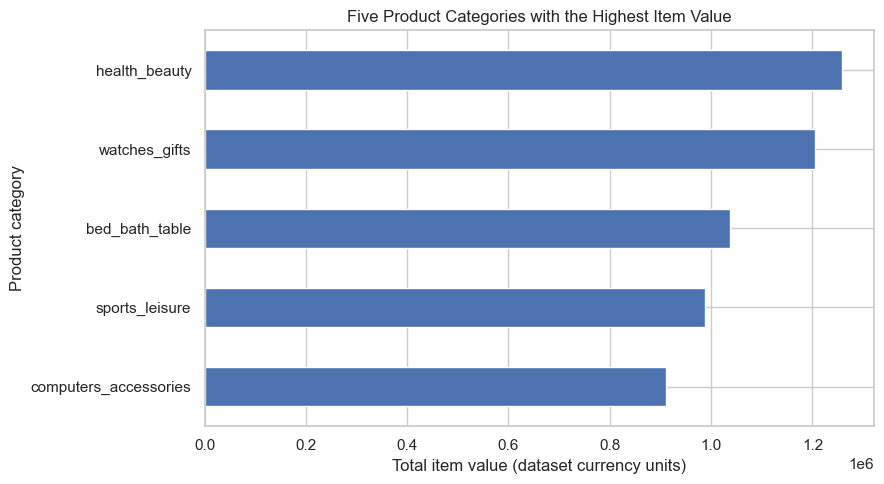

Observation 1: The bars rank the five categories by total item value.
Observation 2: Compare item_count and average_item_price in the table to see whether category totals reflect volume, price, or both.


In [6]:
# Attach English product category names to item rows.
items_category = items_fe.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)
items_category = items_category.merge(
    category_translation,
    on="product_category_name",
    how="left",
    validate="many_to_one"
)
items_category["category_name"] = items_category["product_category_name_english"].fillna(
    items_category["product_category_name"]
).fillna("unknown")

# Aggregate several measures for each product category.
category_summary = (
    items_category.groupby("category_name", dropna=False)
    .agg(
        item_count=("order_id", "size"),
        total_item_value=("line_value", "sum"),
        average_item_price=("price", "mean"),
        median_item_price=("price", "median"),
        average_freight=("freight_value", "mean"),
        minimum_price=("price", "min"),
        maximum_price=("price", "max")
    )
    .sort_values("total_item_value", ascending=False)
)
display(category_summary.head(15))

# Use transform to return each category's average price to every item row.
items_category["category_mean_price"] = (
    items_category.groupby("category_name")["price"].transform("mean")
)

# Calculate how far each item price is from its category average.
items_category["difference_from_category_mean"] = (
    items_category["price"] - items_category["category_mean_price"]
)
display(items_category[[
    "product_id", "category_name", "price", "category_mean_price",
    "difference_from_category_mean"
]].head())

# Compare the five categories with the highest total item value.
top_categories = category_summary.head(5).sort_values("total_item_value")
ax = top_categories["total_item_value"].plot(kind="barh", figsize=(9, 5))
ax.set_title("Five Product Categories with the Highest Item Value")
ax.set_xlabel("Total item value (dataset currency units)")
ax.set_ylabel("Product category")
plt.tight_layout()
plt.show()

print("Observation 1: The bars rank the five categories by total item value.")
print("Observation 2: Compare item_count and average_item_price in the table to see whether category totals reflect volume, price, or both.")

**Interpretation:** `category_summary` is an aggregated table with one row per category. `category_mean_price` is different: it has one value per original item row because `transform()` preserves row alignment. The chart compares the categories with the highest summed item price.

## 9. Pivot Tables and Crosstabulation
**Objective:** Compare a numerical measure across two categorical dimensions and count combinations of categories.  
**Concept:** A pivot table aggregates a numerical measure. A crosstab counts combinations of categorical values.

In [7]:
# Create an order-level monthly item-value summary.
order_item_value = items_fe.groupby("order_id", as_index=False).agg(
    order_item_value=("line_value", "sum")
)
orders_for_pivot = orders_fe.merge(
    order_item_value, on="order_id", how="left", validate="one_to_one"
)
orders_for_pivot["purchase_month_name"] = orders_for_pivot["order_purchase_timestamp"].dt.month_name()

# Pivot: average order item value by purchase year and month.
monthly_pivot = pd.pivot_table(
    orders_for_pivot,
    index="purchase_year",
    columns="purchase_month_name",
    values="order_item_value",
    aggfunc="mean"
)
display(monthly_pivot)

# Crosstab: order status against purchase year.
status_year_crosstab = pd.crosstab(
    orders_for_pivot["purchase_year"],
    orders_for_pivot["order_status"],
    margins=True
)
display(status_year_crosstab)

# Also show row-normalised proportions to compare years of different sizes.
status_year_proportion = pd.crosstab(
    orders_for_pivot["purchase_year"],
    orders_for_pivot["order_status"],
    normalize="index"
)
display(status_year_proportion.round(3))

purchase_month_name,April,August,December,February,January,July,June,March,May,November,October,September
purchase_year,,,,,,,,,,,,
2016,NaN,NaN,10.90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,160.74,89.12
2017,150.53,133.70,132.27,142.70,152.49,125.48,134.61,141.74,138.27,135.59,145.41,147.16
2018,143.73,132.47,NaN,126.11,131.58,142.76,140.44,136.79,145.41,NaN,NaN,145.00


order_status,approved,canceled,created,delivered,invoiced,processing,shipped,unavailable,All
purchase_year,,,,,,,,,
2016,0,26,0,267,18,2,9,7,329
2017,2,265,4,43428,175,240,530,457,45101
2018,0,334,1,52783,121,59,568,145,54011
All,2,625,5,96478,314,301,1107,609,99441


order_status,approved,canceled,created,delivered,invoiced,processing,shipped,unavailable
purchase_year,,,,,,,,
2016,0.00,0.08,0.00,0.81,0.06,0.01,0.03,0.02
2017,0.00,0.01,0.00,0.96,0.00,0.01,0.01,0.01
2018,0.00,0.01,0.00,0.98,0.00,0.00,0.01,0.00


**Interpretation and observations:** The pivot table compares mean order item value by year and month. The crosstab gives the number of orders in each status/year combination. The normalised version expresses each status as a proportion within its year.

## 10. Data Reshaping
**Objective:** Demonstrate `melt()`, `pivot()`, `stack()` and `unstack()`.  
**Concept:** Wide data stores separate measurements in columns. Long data stores the measurement name in one column and its value in another. Reshaping is useful for plotting, comparison and analysis.

In [8]:
# Build a small wide table from the monthly pivot for a clear melt demonstration.
wide_example = monthly_pivot.reset_index().head(3)
display(wide_example)

# Melt month columns into a variable/value pair to create long-format data.
long_example = wide_example.melt(
    id_vars="purchase_year",
    var_name="purchase_month",
    value_name="mean_order_item_value"
)
display(long_example.head(10))

# Pivot the long data back to wide format; year/month combinations are unique here.
pivot_back = long_example.pivot(
    index="purchase_year",
    columns="purchase_month",
    values="mean_order_item_value"
)
display(pivot_back)

# Stack moves the column labels into an additional index level.
stacked_example = monthly_pivot.stack()
display(stacked_example.head(10))

# Unstack moves the innermost index level back into columns.
unstacked_example = stacked_example.unstack()
display(unstacked_example.head())

purchase_month_name,purchase_year,April,August,December,February,January,July,June,March,May,November,October,September
0,2016,NaN,NaN,10.90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,160.74,89.12
1,2017,150.53,133.70,132.27,142.70,152.49,125.48,134.61,141.74,138.27,135.59,145.41,147.16
2,2018,143.73,132.47,NaN,126.11,131.58,142.76,140.44,136.79,145.41,NaN,NaN,145.00


,purchase_year,purchase_month,mean_order_item_value
0,2016,April,NaN
1,2017,April,150.53
2,2018,April,143.73
3,2016,August,NaN
4,2017,August,133.70
5,2018,August,132.47
6,2016,December,10.90
7,2017,December,132.27
8,2018,December,NaN
9,2016,February,NaN


purchase_month,April,August,December,February,January,July,June,March,May,November,October,September
purchase_year,,,,,,,,,,,,
2016,NaN,NaN,10.90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,160.74,89.12
2017,150.53,133.70,132.27,142.70,152.49,125.48,134.61,141.74,138.27,135.59,145.41,147.16
2018,143.73,132.47,NaN,126.11,131.58,142.76,140.44,136.79,145.41,NaN,NaN,145.00


purchase_year  purchase_month_name
2016           December               10.90
               October               160.74
               September              89.12
2017           April                 150.53
               August                133.70
               December              132.27
               February              142.70
               January               152.49
               July                  125.48
               June                  134.61
dtype: float64

purchase_month_name,April,August,December,February,January,July,June,March,May,November,October,September
purchase_year,,,,,,,,,,,,
2016,NaN,NaN,10.90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,160.74,89.12
2017,150.53,133.70,132.27,142.70,152.49,125.48,134.61,141.74,138.27,135.59,145.41,147.16
2018,143.73,132.47,NaN,126.11,131.58,142.76,140.44,136.79,145.41,NaN,NaN,145.00


**Interpretation:** `melt()` changed month columns into rows. `pivot()` reconstructed the wide layout. `stack()` moved column labels into the index, and `unstack()` moved an index level back into columns. These operations change layout, not the underlying observations. The example uses a limited subset of the real monthly pivot to keep the output readable.

## 11. Data Integration
**Objective:** Integrate related tables and demonstrate merge, join and concat, join types, suffixes, key validation, unmatched records, index alignment and row-count changes.  
**Integration plan:**

| Parent table | Child / lookup table | Key | Expected relationship | Purpose |
|---|---|---|---|---|
| orders | customers | customer_id | many-to-one | add customer state |
| orders | item summary | order_id | one-to-one after aggregation | add order item value |
| orders | payment summary | order_id | one-to-one after aggregation | add payment total |
| orders | review summary | order_id | one-to-one after aggregation | add review score |

Child tables are aggregated to one row per order before combining them. This avoids multiplying item rows by payment rows or review rows.

In [9]:
# Summarise each child table to one row per order before integration.
item_order_summary = items_fe.groupby("order_id", as_index=False).agg(
    item_count=("order_item_id", "count"),
    item_value=("price", "sum"),
    freight_total=("freight_value", "sum")
)
payment_order_summary = payments.groupby("order_id", as_index=False).agg(
    payment_total=("payment_value", "sum"),
    payment_record_count=("payment_sequential", "count")
)
review_order_summary = reviews.groupby("order_id", as_index=False).agg(
    average_review_score=("review_score", "mean"),
    review_record_count=("review_id", "count")
)

# Print row counts before merging to make changes visible.
print("Orders before integration:", len(orders_fe))
print("Item summary rows:", len(item_order_summary))
print("Payment summary rows:", len(payment_order_summary))
print("Review summary rows:", len(review_order_summary))

# Check whether the aggregated child keys are unique.
print("Duplicate item-summary order keys:", item_order_summary["order_id"].duplicated().sum())
print("Duplicate payment-summary order keys:", payment_order_summary["order_id"].duplicated().sum())
print("Duplicate review-summary order keys:", review_order_summary["order_id"].duplicated().sum())

# Merge orders with customers; many orders can reference one customer record.
orders_customers = orders_fe.merge(
    customers, on="customer_id", how="left",
    validate="many_to_one", indicator="customer_merge"
)
display(orders_customers["customer_merge"].value_counts())

# Merge each one-row-per-order summary using one-to-one validation.
integrated = orders_customers.merge(
    item_order_summary, on="order_id", how="left",
    validate="one_to_one", suffixes=("", "_item"), indicator="item_merge"
)
integrated = integrated.merge(
    payment_order_summary, on="order_id", how="left",
    validate="one_to_one", suffixes=("", "_payment"), indicator="payment_merge"
)
integrated = integrated.merge(
    review_order_summary, on="order_id", how="left",
    validate="one_to_one", suffixes=("", "_review"), indicator="review_merge"
)

# Report final row count and match status for the important merges.
print("Rows after integrated merges:", len(integrated))
for indicator in ["item_merge", "payment_merge", "review_merge"]:
    print(f"\n{indicator}")
    print(integrated[indicator].value_counts(dropna=False))

# Show the integrated analytical table.
display(integrated[[
    "order_id", "customer_state", "order_status", "item_count",
    "item_value", "freight_total", "payment_total", "average_review_score"
]].head())

Orders before integration: 99441
Item summary rows: 98666
Payment summary rows: 99440
Review summary rows: 98673
Duplicate item-summary order keys: 0
Duplicate payment-summary order keys: 0
Duplicate review-summary order keys: 0


customer_merge
both          99441
left_only         0
right_only        0
Name: count, dtype: int64

Rows after integrated merges: 99441

item_merge
item_merge
both          98666
left_only       775
right_only        0
Name: count, dtype: int64

payment_merge
payment_merge
both          99440
left_only         1
right_only        0
Name: count, dtype: int64

review_merge
review_merge
both          98673
left_only       768
right_only        0
Name: count, dtype: int64


,order_id,customer_state,order_status,item_count,item_value,freight_total,payment_total,average_review_score
0,e481f51cbdc54678b7cc49136f2d6af7,SP,delivered,1.00,29.99,8.72,38.71,4.00
1,53cdb2fc8bc7dce0b6741e2150273451,BA,delivered,1.00,118.70,22.76,141.46,4.00
2,47770eb9100c2d0c44946d9cf07ec65d,GO,delivered,1.00,159.90,19.22,179.12,5.00
3,949d5b44dbf5de918fe9c16f97b45f8a,RN,delivered,1.00,45.00,27.20,72.20,5.00
4,ad21c59c0840e6cb83a9ceb5573f8159,SP,delivered,1.00,19.90,8.72,28.62,5.00


**Interpretation:** The `validate` argument checks the expected relationship at merge time. The merge indicators distinguish matched and unmatched order keys. The child summaries are one row per order, so merging them does not multiply order rows. A missing child match is reported rather than silently filled with a fabricated value.  
**Decision:** Keep the order-level table as the analysis grain. Item-level details remain available separately in `items_fe` and `items_category`.

In [10]:
# Demonstrate inner, left, right and outer join retention on order IDs.
left_demo = orders_fe[["order_id", "order_status"]].head(100).copy()
right_demo = item_order_summary[["order_id", "item_value"]].head(100).copy()

join_counts = {}
for join_type in ["inner", "left", "right", "outer"]:
    joined = left_demo.merge(right_demo, on="order_id", how=join_type, indicator=True)
    join_counts[join_type] = {
        "rows_after_join": len(joined),
        "both": int((joined["_merge"] == "both").sum()),
        "left_only": int((joined["_merge"] == "left_only").sum()),
        "right_only": int((joined["_merge"] == "right_only").sum())
    }
display(pd.DataFrame(join_counts).T)

# Demonstrate join() using the order ID as an index.
orders_indexed = left_demo.set_index("order_id")
items_indexed = right_demo.set_index("order_id")
joined_by_index = orders_indexed.join(
    items_indexed, how="left", lsuffix="_order", rsuffix="_item"
)
display(joined_by_index.head())

# Demonstrate concat() by appending two non-overlapping row slices.
first_part = item_order_summary.iloc[:5].copy()
second_part = item_order_summary.iloc[5:10].copy()
concatenated = pd.concat([first_part, second_part], axis=0, ignore_index=True)
display(concatenated)

# Demonstrate index alignment when two Series are combined.
status_series = left_demo.set_index("order_id")["order_status"]
value_series = right_demo.set_index("order_id")["item_value"]
aligned_series = pd.concat([status_series, value_series], axis=1)
display(aligned_series.head())

,rows_after_join,both,left_only,right_only
inner,0,0,0,0
left,100,0,100,0
right,100,0,0,100
outer,200,0,100,100


,order_status,item_value
order_id,,
e481f51cbdc54678b7cc49136f2d6af7,delivered,NaN
53cdb2fc8bc7dce0b6741e2150273451,delivered,NaN
47770eb9100c2d0c44946d9cf07ec65d,delivered,NaN
949d5b44dbf5de918fe9c16f97b45f8a,delivered,NaN
ad21c59c0840e6cb83a9ceb5573f8159,delivered,NaN


,order_id,item_count,item_value,freight_total
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,18.14
5,00048cc3ae777c65dbb7d2a0634bc1ea,1,21.90,12.69
6,00054e8431b9d7675808bcb819fb4a32,1,19.90,11.85
7,000576fe39319847cbb9d288c5617fa6,1,810.00,70.75
8,0005a1a1728c9d785b8e2b08b904576c,1,145.95,11.65
9,0005f50442cb953dcd1d21e1fb923495,1,53.99,11.40


,order_status,item_value
order_id,,
e481f51cbdc54678b7cc49136f2d6af7,delivered,NaN
53cdb2fc8bc7dce0b6741e2150273451,delivered,NaN
47770eb9100c2d0c44946d9cf07ec65d,delivered,NaN
949d5b44dbf5de918fe9c16f97b45f8a,delivered,NaN
ad21c59c0840e6cb83a9ceb5573f8159,delivered,NaN


## 12. Descriptive Statistics
**Objective:** Calculate central tendency, dispersion, percentiles, quantiles, five-number summary, skewness and kurtosis for suitable numerical variables.  
**Convention:** Variance and standard deviation below use the sample convention (`ddof=1`). Monetary values are in the dataset's currency units; duration is measured in days. Pandas reports Fisher/excess kurtosis, where a normal distribution has kurtosis near zero.

In [11]:
# Select numerical variables with clear meanings and units.
statistics_data = integrated[[
    "item_value", "freight_total", "payment_total",
    "delivery_days", "average_review_score"
]].copy()

# Calculate mean, median and mode for each numerical variable.
central_tendency = pd.DataFrame({
    "mean": statistics_data.mean(),
    "median": statistics_data.median(),
    "mode": statistics_data.mode().iloc[0]
})
display(central_tendency)

# Calculate sample variance, sample standard deviation and range.
dispersion = pd.DataFrame({
    "sample_variance": statistics_data.var(ddof=1),
    "sample_standard_deviation": statistics_data.std(ddof=1),
    "minimum": statistics_data.min(),
    "maximum": statistics_data.max(),
    "range": statistics_data.max() - statistics_data.min()
})
display(dispersion)

# Calculate selected percentiles and quartiles.
percentiles = statistics_data.quantile([0.10, 0.25, 0.50, 0.75, 0.90])
display(percentiles)

# Calculate the five-number summary for every selected variable.
five_number_summary = pd.DataFrame({
    "minimum": statistics_data.min(),
    "Q1": statistics_data.quantile(0.25),
    "median": statistics_data.quantile(0.50),
    "Q3": statistics_data.quantile(0.75),
    "maximum": statistics_data.max()
})
display(five_number_summary)

# Calculate skewness and Fisher/excess kurtosis.
shape_statistics = pd.DataFrame({
    "skewness": statistics_data.skew(),
    "excess_kurtosis_fisher": statistics_data.kurt()
})
display(shape_statistics)

,mean,median,mode
item_value,137.75,86.90,59.90
freight_total,22.82,17.17,15.10
payment_total,160.99,105.29,77.57
delivery_days,12.56,10.22,2.07
average_review_score,4.09,5.00,5.00


,sample_variance,sample_standard_deviation,minimum,maximum,range
item_value,"44,371.38",210.65,0.85,"13,440.00","13,439.15"
freight_total,468.76,21.65,0.00,"1,794.96","1,794.96"
payment_total,"49,262.36",221.95,0.00,"13,664.08","13,664.08"
delivery_days,91.14,9.55,0.53,209.63,209.10
average_review_score,1.81,1.35,1.00,5.00,4.00


,item_value,freight_total,payment_total,delivery_days,average_review_score
0.10,25.00,9.34,39.60,4.16,1.00
0.25,45.90,13.85,62.01,6.77,4.00
0.50,86.90,17.17,105.29,10.22,5.00
0.75,149.90,24.04,176.97,15.72,5.00
0.90,269.90,39.50,308.24,23.10,5.00


,minimum,Q1,median,Q3,maximum
item_value,0.85,45.90,86.90,149.90,"13,440.00"
freight_total,0.00,13.85,17.17,24.04,"1,794.96"
payment_total,0.00,62.01,105.29,176.97,"13,664.08"
delivery_days,0.53,6.77,10.22,15.72,209.63
average_review_score,1.00,4.00,5.00,5.00,5.00


,skewness,excess_kurtosis_fisher
item_value,9.73,266.07
freight_total,12.05,565.34
payment_total,9.15,233.41
delivery_days,3.83,39.31
average_review_score,-1.36,0.51


## 13. Distribution Analysis
**Objective:** Use histograms, density curves and box plots to inspect real numerical distributions. Identify normal-like, positively skewed, negatively skewed and bimodal shapes only when the observed plots support those descriptions.  
**Method:** The notebook plots item value, delivery duration and review score. These are real dataset variables. If a required shape is not clearly present, the limitation is stated and a labelled simulation is used rather than mislabelling real data.

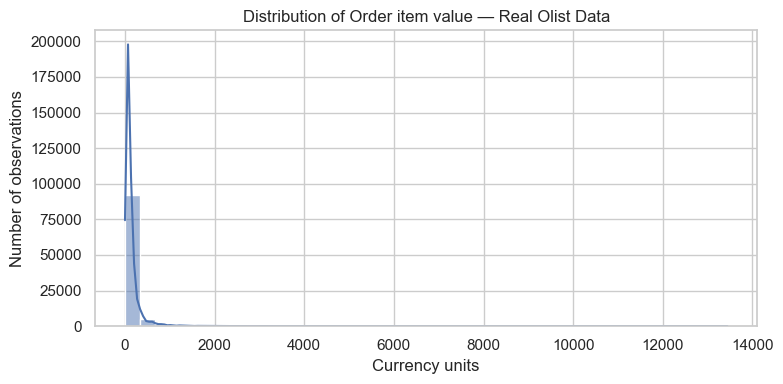

Observation 1: The histogram shows the observed shape of order item value.
Observation 2: Compare the histogram's tail balance and peaks with the descriptive skewness and kurtosis values above.


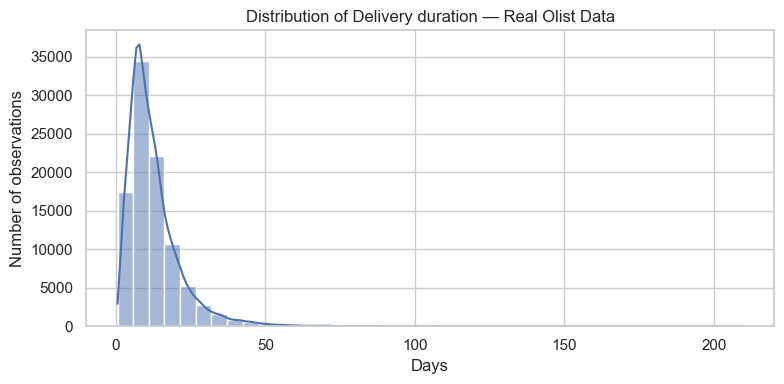

Observation 1: The histogram shows the observed shape of delivery duration.
Observation 2: Compare the histogram's tail balance and peaks with the descriptive skewness and kurtosis values above.


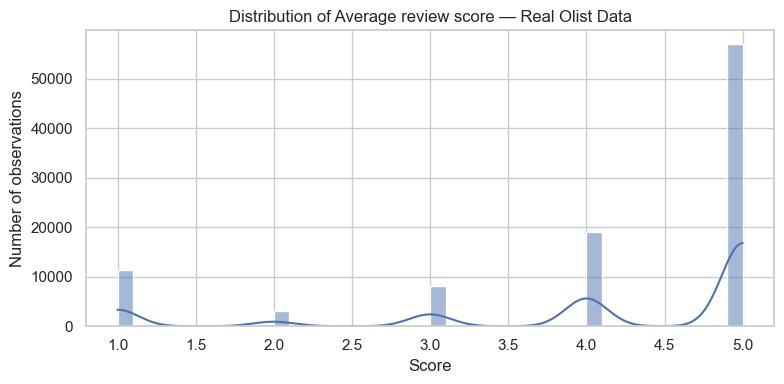

Observation 1: The histogram shows the observed shape of average review score.
Observation 2: Compare the histogram's tail balance and peaks with the descriptive skewness and kurtosis values above.


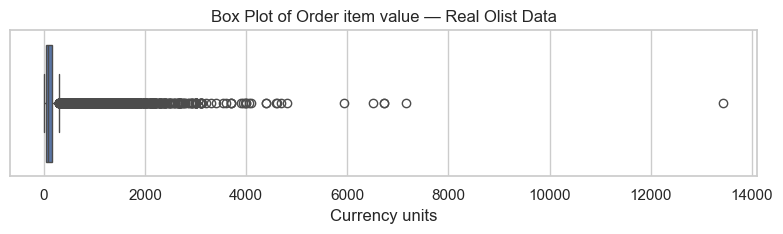

Observation 1: The box shows the interquartile range and the line inside it is the median.
Observation 2: Points beyond the whiskers are potential outliers, not automatically data errors.


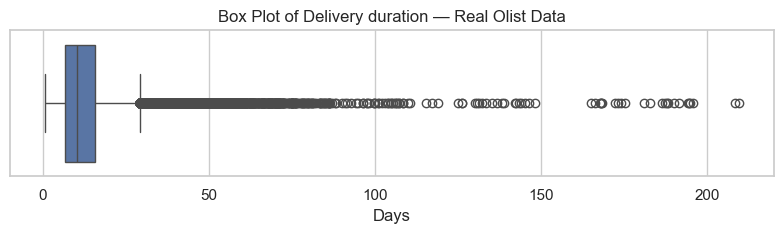

Observation 1: The box shows the interquartile range and the line inside it is the median.
Observation 2: Points beyond the whiskers are potential outliers, not automatically data errors.


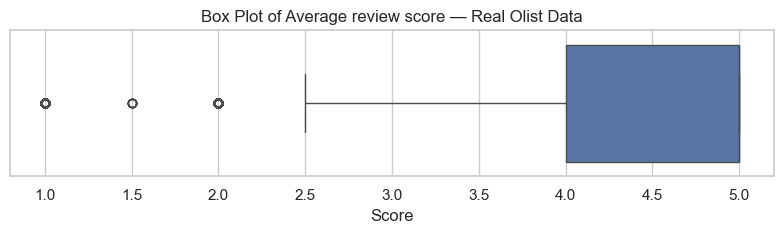

Observation 1: The box shows the interquartile range and the line inside it is the median.
Observation 2: Points beyond the whiskers are potential outliers, not automatically data errors.


In [12]:
# Define the real variables to inspect and their units.
distribution_variables = {
    "item_value": ("Order item value", "Currency units"),
    "delivery_days": ("Delivery duration", "Days"),
    "average_review_score": ("Average review score", "Score")
}

# Draw a histogram and density curve for each real variable.
for column, (title, unit) in distribution_variables.items():
    values = statistics_data[column].dropna()
    plt.figure(figsize=(8, 4))
    sns.histplot(values, bins=40, kde=True)
    plt.title(f"Distribution of {title} — Real Olist Data")
    plt.xlabel(unit)
    plt.ylabel("Number of observations")
    plt.tight_layout()
    plt.show()
    print(f"Observation 1: The histogram shows the observed shape of {title.lower()}.")
    print("Observation 2: Compare the histogram's tail balance and peaks with the descriptive skewness and kurtosis values above.")

# Draw box plots for the same variables to compare spread and extreme values.
for column, (title, unit) in distribution_variables.items():
    plt.figure(figsize=(8, 2.5))
    sns.boxplot(x=statistics_data[column])
    plt.title(f"Box Plot of {title} — Real Olist Data")
    plt.xlabel(unit)
    plt.tight_layout()
    plt.show()
    print("Observation 1: The box shows the interquartile range and the line inside it is the median.")
    print("Observation 2: Points beyond the whiskers are potential outliers, not automatically data errors.")

**Distribution decision:** Inspect each generated plot and the corresponding skewness value. A right tail supports positive skew; a left tail supports negative skew. A roughly symmetric, single-peaked histogram may be approximately normal. Two visible peaks may indicate a bimodal mixture, but should be checked against subgroups. Do not claim that a real variable is normal or bimodal unless the displayed plot supports it.

### Controlled distribution demonstration (only if the real data do not show all required shapes)
The following values are simulated, not Olist observations. They provide clearly labelled examples of normal, positively skewed, negatively skewed and bimodal shapes when the real variables do not naturally provide a clear example. The fixed seed makes the simulation repeatable.

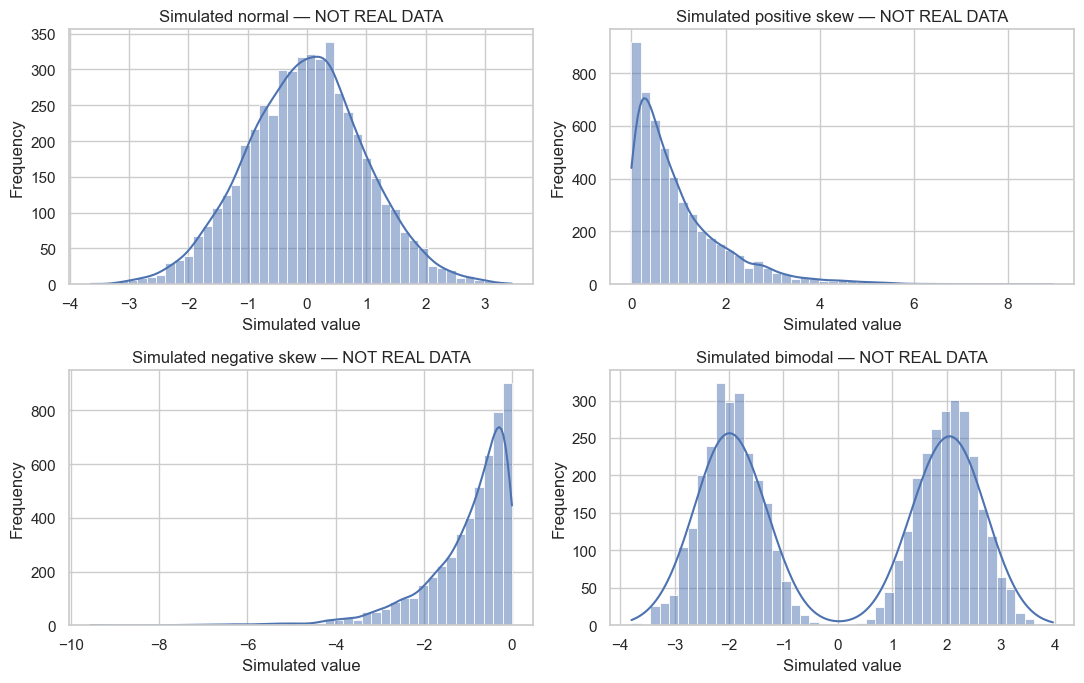

,distribution,skewness
0,Simulated normal,0.00
1,Simulated positive skew,1.91
2,Simulated negative skew,-2.08
3,Simulated bimodal,0.00


In [13]:
# Create controlled simulated distributions using a fixed random seed.
rng = np.random.default_rng(RANDOM_SEED)
simulated_shapes = {
    "Simulated normal": rng.normal(loc=0, scale=1, size=5000),
    "Simulated positive skew": rng.exponential(scale=1, size=5000),
    "Simulated negative skew": -rng.exponential(scale=1, size=5000),
    "Simulated bimodal": np.concatenate([
        rng.normal(loc=-2, scale=0.55, size=2500),
        rng.normal(loc=2, scale=0.55, size=2500)
    ])
}

# Plot each simulated distribution and label it clearly as simulated.
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for axis, (label, values) in zip(axes.flat, simulated_shapes.items()):
    sns.histplot(values, bins=45, kde=True, ax=axis)
    axis.set_title(label + " — NOT REAL DATA")
    axis.set_xlabel("Simulated value")
    axis.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

# Print skewness to support the visual comparison.
display(pd.DataFrame({
    "distribution": list(simulated_shapes.keys()),
    "skewness": [pd.Series(values).skew() for values in simulated_shapes.values()]
}))

**Interpretation:** The simulation is a controlled illustration only. It must not be mixed with Olist records or reported as a finding about Olist. It is included to explain the shapes if the actual dataset does not clearly contain each one.

## 14. Empirical Rule (68–95–99.7 Rule)
**Objective:** Compare observed percentages within one, two and three standard deviations of the mean with the theoretical normal-distribution percentages.  
**Method:** Use a real variable only if its histogram is reasonably bell-shaped. The code calculates observed percentages for delivery duration; interpret the comparison cautiously if its distribution is skewed. A simulated normal sample is also shown as a controlled reference.

In [14]:
# Select non-missing real delivery durations.
real_values = statistics_data["delivery_days"].dropna()

# Calculate the real-data mean and sample standard deviation.
real_mean = real_values.mean()
real_sd = real_values.std(ddof=1)

# Calculate the observed percentage within each standard-deviation interval.
empirical_rows = []
for number_of_sd, theoretical_percent in [(1, 68), (2, 95), (3, 99.7)]:
    lower = real_mean - number_of_sd * real_sd
    upper = real_mean + number_of_sd * real_sd
    observed_percent = 100 * real_values.between(lower, upper).mean()
    empirical_rows.append({
        "interval": f"mean ± {number_of_sd} SD",
        "observed_percent": observed_percent,
        "normal_reference_percent": theoretical_percent
    })
display(pd.DataFrame(empirical_rows))

# Generate a clearly labelled normal simulation for a reference comparison.
normal_reference = rng.normal(loc=0, scale=1, size=10000)
normal_mean = normal_reference.mean()
normal_sd = normal_reference.std(ddof=1)
simulation_rows = []
for number_of_sd, theoretical_percent in [(1, 68), (2, 95), (3, 99.7)]:
    inside = normal_reference.between if False else None
    observed = 100 * (
        (normal_reference >= normal_mean - number_of_sd * normal_sd)
        & (normal_reference <= normal_mean + number_of_sd * normal_sd)
    ).mean()
    simulation_rows.append({
        "interval": f"mean ± {number_of_sd} SD",
        "simulated_normal_percent": observed,
        "normal_reference_percent": theoretical_percent
    })
display(pd.DataFrame(simulation_rows))

,interval,observed_percent,normal_reference_percent
0,mean ± 1 SD,83.80,68.00
1,mean ± 2 SD,95.98,95.00
2,mean ± 3 SD,98.37,99.70


,interval,simulated_normal_percent,normal_reference_percent
0,mean ± 1 SD,68.09,68.00
1,mean ± 2 SD,95.26,95.00
2,mean ± 3 SD,99.82,99.70


**Interpretation:** For a normal, bell-shaped distribution, approximately 68%, 95% and 99.7% of observations lie within one, two and three standard deviations of the mean. Compare the observed Olist percentages with these reference values. Large differences may occur because delivery durations are skewed or heavy-tailed. The simulated normal values are a controlled reference, not actual orders. The empirical rule is not expected to work well for highly skewed, heavy-tailed or bimodal distributions.

## 15. Sampling and Central Limit Theorem
**Objective:** Demonstrate sampling variability by repeatedly drawing random samples and plotting their means.  
  
**Method:** Use simple random sampling without replacement within each repetition, fixed seed, 500 repetitions and sample sizes 10, 30 and 100.

,mean,std,min,max
sample_size,,,,
10,136.35,58.84,49.44,540.73
30,140.78,40.26,68.57,380.02
100,137.39,20.43,94.94,254.94


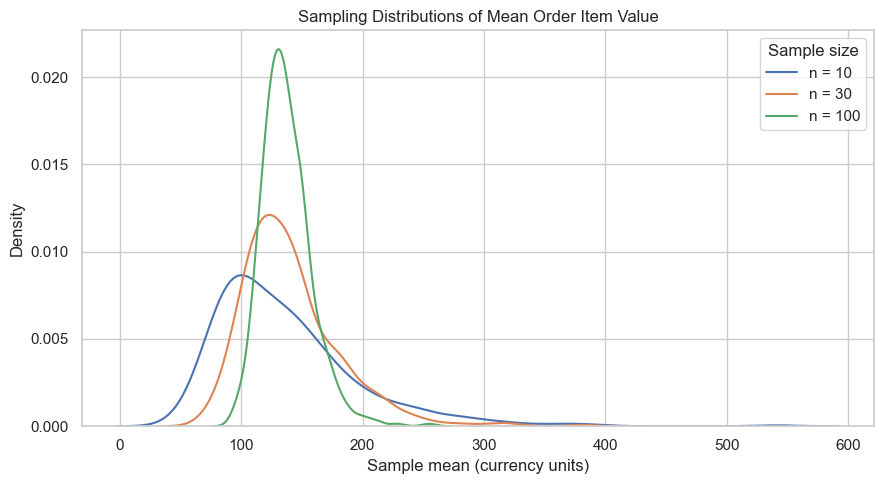

Observation 1: Each curve represents 500 sample means for the stated sample size.
Observation 2: Compare the standard deviations in the summary; larger samples generally produce less variable sample means.


In [15]:
# Define the source population as observed order item values.
population_values = statistics_data["item_value"].dropna().to_numpy()

# Set the number of repeated samples and sample sizes.
REPETITIONS = 500
SAMPLE_SIZES = [10, 30, 100]
sampling_rng = np.random.default_rng(RANDOM_SEED)

# Draw repeated samples and store the mean from each sample.
sample_mean_results = []
for sample_size in SAMPLE_SIZES:
    for repetition in range(REPETITIONS):
        sample = sampling_rng.choice(
            population_values,
            size=sample_size,
            replace=False
        )
        sample_mean_results.append({
            "sample_size": sample_size,
            "repetition": repetition + 1,
            "sample_mean": sample.mean()
        })
sample_means = pd.DataFrame(sample_mean_results)

# Summarise the sampling distributions for each sample size.
sampling_summary = sample_means.groupby("sample_size")["sample_mean"].agg(
    ["mean", "std", "min", "max"]
)
display(sampling_summary)

# Plot the distributions of the repeated sample means.
plt.figure(figsize=(9, 5))
for sample_size in SAMPLE_SIZES:
    sns.kdeplot(
        data=sample_means.loc[sample_means["sample_size"] == sample_size],
        x="sample_mean",
        label=f"n = {sample_size}"
    )
plt.title("Sampling Distributions of Mean Order Item Value")
plt.xlabel("Sample mean (currency units)")
plt.ylabel("Density")
plt.legend(title="Sample size")
plt.tight_layout()
plt.show()

print("Observation 1: Each curve represents 500 sample means for the stated sample size.")
print("Observation 2: Compare the standard deviations in the summary; larger samples generally produce less variable sample means.")

**Interpretation:** Each repetition uses a new simple random sample from the available order-value population. Sample means vary because the selected records vary. As sample size increases, the spread of sample means generally decreases and the distribution tends to become more nearly normal under CLT conditions.

## 16. Correlation Analysis
**Objective:** Calculate covariance, Pearson correlation and Spearman correlation; create a labelled correlation heatmap and scatter plots.  
**Concept:** Covariance shows whether two variables tend to vary together but depends on their units. Pearson correlation measures linear association and Spearman correlation measures monotonic rank association. Both correlations range from −1 to +1. Correlation does not prove causation.

,item_value,freight_total,payment_total,delivery_days,delivery_delay_days,average_review_score
item_value,"43,174.13","1,832.18","45,009.02",108.73,-31.22,-9.26
freight_total,"1,832.18",463.20,"2,295.95",34.09,-11.03,-2.48
payment_total,"45,009.02","2,295.95","47,309.56",142.89,-42.34,-11.76
delivery_days,108.73,34.09,142.89,89.49,57.52,-4.06
delivery_delay_days,-31.22,-11.03,-42.34,57.52,102.31,-3.46
average_review_score,-9.26,-2.48,-11.76,-4.06,-3.46,1.65


,item_value,freight_total,payment_total,delivery_days,delivery_delay_days,average_review_score
item_value,1.00,0.41,1.00,0.06,-0.01,-0.03
freight_total,0.41,1.00,0.49,0.17,-0.05,-0.09
payment_total,1.00,0.49,1.00,0.07,-0.02,-0.04
delivery_days,0.06,0.17,0.07,1.00,0.60,-0.33
delivery_delay_days,-0.01,-0.05,-0.02,0.60,1.00,-0.27
average_review_score,-0.03,-0.09,-0.04,-0.33,-0.27,1.00


,item_value,freight_total,payment_total,delivery_days,delivery_delay_days,average_review_score
item_value,1.00,0.47,0.99,0.10,-0.04,-0.03
freight_total,0.47,1.00,0.57,0.38,-0.16,-0.09
payment_total,0.99,0.57,1.00,0.14,-0.06,-0.04
delivery_days,0.10,0.38,0.14,1.00,0.31,-0.23
delivery_delay_days,-0.04,-0.16,-0.06,0.31,1.00,-0.18
average_review_score,-0.03,-0.09,-0.04,-0.23,-0.18,1.00


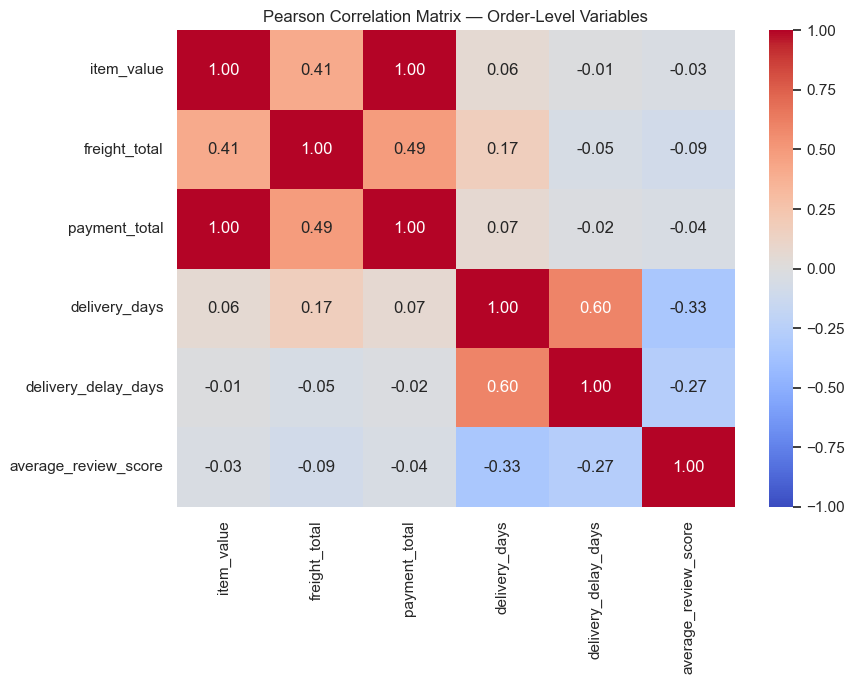

Observation 1: Values near +1 indicate strong positive linear association; values near -1 indicate strong negative linear association.
Observation 2: Values near 0 indicate weak linear association, not necessarily the absence of every possible relationship.


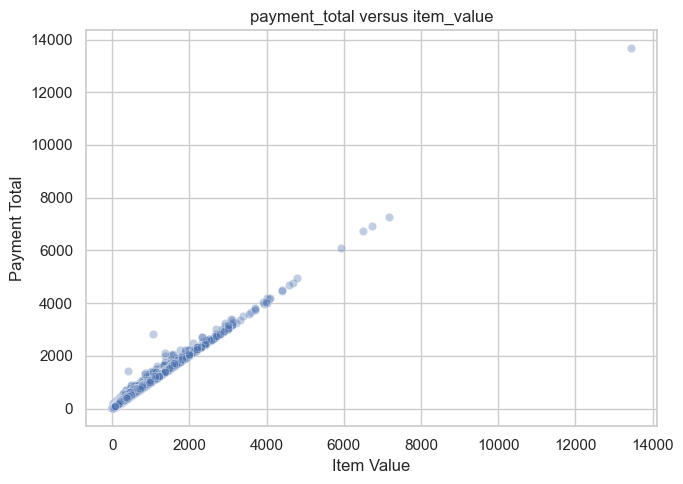

Observation 1: Inspect the point cloud to judge direction, spread and possible extreme observations for item_value and payment_total.
Observation 2: Compare the plot with Pearson and Spearman coefficients; a difference can suggest outlier influence or a non-linear monotonic pattern.


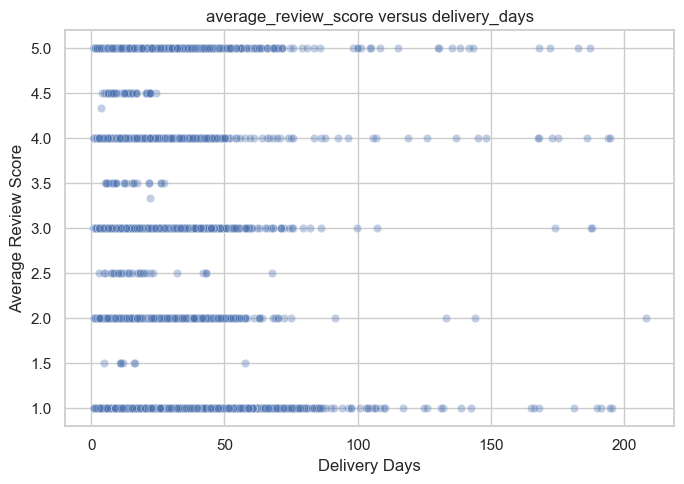

Observation 1: Inspect the point cloud to judge direction, spread and possible extreme observations for delivery_days and average_review_score.
Observation 2: Compare the plot with Pearson and Spearman coefficients; a difference can suggest outlier influence or a non-linear monotonic pattern.


,pearson,spearman
item_value vs payment_total,1.00,0.99
delivery_days vs average_review_score,-0.33,-0.23


In [16]:
# Select numerical order-level variables for relationship analysis.
correlation_data = integrated[[
    "item_value", "freight_total", "payment_total",
    "delivery_days", "delivery_delay_days", "average_review_score"
]].dropna()

# Calculate covariance using the sample convention.
covariance_matrix = correlation_data.cov()
display(covariance_matrix)

# Calculate Pearson correlation for linear association.
pearson_matrix = correlation_data.corr(method="pearson")
display(pearson_matrix)

# Calculate Spearman correlation for monotonic rank association.
spearman_matrix = correlation_data.corr(method="spearman")
display(spearman_matrix)

# Draw a labelled heatmap of Pearson correlation coefficients.
plt.figure(figsize=(9, 7))
sns.heatmap(
    pearson_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)
plt.title("Pearson Correlation Matrix — Order-Level Variables")
plt.tight_layout()
plt.show()
print("Observation 1: Values near +1 indicate strong positive linear association; values near -1 indicate strong negative linear association.")
print("Observation 2: Values near 0 indicate weak linear association, not necessarily the absence of every possible relationship.")

# Draw scatter plots for important numerical pairs.
for x_column, y_column in [
    ("item_value", "payment_total"),
    ("delivery_days", "average_review_score")
]:
    plt.figure(figsize=(7, 5))
    sns.scatterplot(
        data=correlation_data,
        x=x_column,
        y=y_column,
        alpha=0.35
    )
    plt.title(f"{y_column} versus {x_column}")
    plt.xlabel(x_column.replace("_", " ").title())
    plt.ylabel(y_column.replace("_", " ").title())
    plt.tight_layout()
    plt.show()
    print(f"Observation 1: Inspect the point cloud to judge direction, spread and possible extreme observations for {x_column} and {y_column}.")
    print("Observation 2: Compare the plot with Pearson and Spearman coefficients; a difference can suggest outlier influence or a non-linear monotonic pattern.")

# Display Pearson and Spearman coefficients for the selected pairs.
pair_comparison = pd.DataFrame({
    "pearson": [
        correlation_data["item_value"].corr(correlation_data["payment_total"], method="pearson"),
        correlation_data["delivery_days"].corr(correlation_data["average_review_score"], method="pearson")
    ],
    "spearman": [
        correlation_data["item_value"].corr(correlation_data["payment_total"], method="spearman"),
        correlation_data["delivery_days"].corr(correlation_data["average_review_score"], method="spearman")
    ]
}, index=["item_value vs payment_total", "delivery_days vs average_review_score"])
display(pair_comparison)

**Interpretation:** Read the actual coefficient values and scatter plots generated above. Pearson and Spearman can differ when outliers affect linear association or when a relationship is monotonic but not linear.

## 17. Outlier Detection and Treatment
**Objective:** Detect potential outliers using IQR and Z-score methods, compare counts, and demonstrate removal, capping and retention on separate copies.  
**Method:** The target variable is order item value. IQR fences are Q1 − 1.5×IQR and Q3 + 1.5×IQR. The exploratory Z-score threshold is |Z| > 3. Both methods are screening methods; flagged values must be inspected in context and are not automatically errors.

,method,threshold,outlier_count,outlier_percent
0,IQR,< -110.10 or > 305.90,7913,8.02
1,Z-score (|Z| > 3),|Z| > 3,1709,1.73


,order_id,item_value,item_count,freight_total,order_status
13390,03caa2c082116e1d31e67e9ae3700499,"13,440.00",8.00,224.08,delivered
66599,736e1922ae60d0d6a89247b851902527,"7,160.00",4.00,114.88,delivered
22171,0812eb902a67711a1cb742b3cdaa65ae,"6,735.00",1.00,194.31,delivered
28326,fefacc66af859508bf1a7934eab1e97f,"6,729.00",1.00,193.21,delivered
3508,f5136e38d1a14a4dbd87dff67da82701,"6,499.00",1.00,227.66,delivered
32322,2cc9089445046817a7539d90805e6e5a,"5,934.60",6.00,146.94,delivered
53352,a96610ab360d42a2e5335a3998b4718a,"4,799.00",1.00,151.34,delivered
40327,199af31afc78c699f0dbf71fb178d4d4,"4,690.00",1.00,74.34,delivered
41086,b4c4b76c642808cbe472a32b86cddc95,"4,599.90",2.00,209.54,canceled
40342,8dbc85d1447242f3b127dda390d56e19,"4,590.00",1.00,91.78,delivered


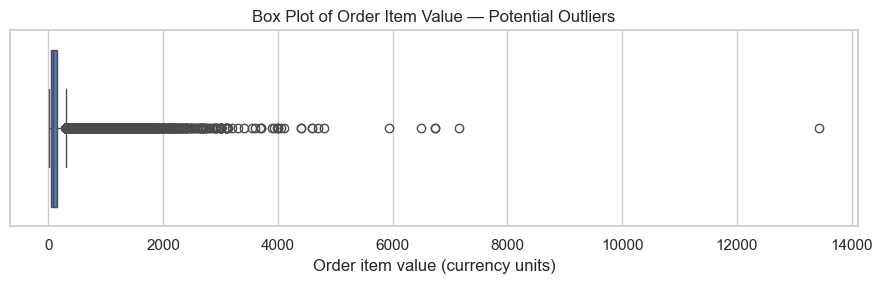

Observation 1: The box plot marks values beyond the whiskers as potential outliers.
Observation 2: IQR and Z-score methods can flag different records because they use different rules and distribution assumptions.


In [17]:
# Create a non-missing series for item-value outlier analysis.
outlier_values = statistics_data["item_value"].dropna()

# Calculate quartiles, IQR and the lower/upper IQR fences.
q1 = outlier_values.quantile(0.25)
q3 = outlier_values.quantile(0.75)
iqr_value = q3 - q1
lower_fence = q1 - 1.5 * iqr_value
upper_fence = q3 + 1.5 * iqr_value

# Flag values outside the IQR fences.
iqr_outlier_mask = (
    (outlier_values < lower_fence) | (outlier_values > upper_fence)
)

# Calculate Z-scores and flag observations beyond the stated threshold.
z_scores = (outlier_values - outlier_values.mean()) / outlier_values.std(ddof=1)
z_outlier_mask = z_scores.abs() > 3

# Report counts and proportions found by each method.
outlier_report = pd.DataFrame({
    "method": ["IQR", "Z-score (|Z| > 3)"],
    "threshold": [f"< {lower_fence:.2f} or > {upper_fence:.2f}", "|Z| > 3"],
    "outlier_count": [int(iqr_outlier_mask.sum()), int(z_outlier_mask.sum())],
    "outlier_percent": [
        100 * iqr_outlier_mask.mean(),
        100 * z_outlier_mask.mean()
    ]
})
display(outlier_report)

# Inspect the largest potential outlier values and their original order IDs.
flagged_order_ids = outlier_values.index[iqr_outlier_mask]
display(integrated.loc[flagged_order_ids, [
    "order_id", "item_value", "item_count", "freight_total", "order_status"
]].sort_values("item_value", ascending=False).head(10))

# Visualise the item-value spread and potential outliers.
plt.figure(figsize=(9, 3))
sns.boxplot(x=outlier_values)
plt.title("Box Plot of Order Item Value — Potential Outliers")
plt.xlabel("Order item value (currency units)")
plt.tight_layout()
plt.show()
print("Observation 1: The box plot marks values beyond the whiskers as potential outliers.")
print("Observation 2: IQR and Z-score methods can flag different records because they use different rules and distribution assumptions.")

**Interpretation:** IQR uses quartiles and is relatively robust to extreme values. Z-scores use the mean and standard deviation and can be influenced by skewness and extreme values. The displayed source records should be inspected before any treatment decision. A high order value can be a genuine large purchase rather than an error.

In [18]:
# Keep the complete order-level analysis values in an unchanged series.
original_values = integrated["item_value"].copy()

# Strategy 1 — removal: create a separate copy excluding IQR-flagged observations.
removal_copy = integrated.loc[
    integrated["item_value"].isna() | ~integrated["item_value"].index.isin(flagged_order_ids)
].copy()

# Strategy 2 — capping: create a separate copy and cap valid values at IQR fences.
capping_copy = integrated.copy()
capping_copy["item_value_capped"] = capping_copy["item_value"].clip(
    lower=lower_fence,
    upper=upper_fence
)

# Strategy 3 — retention: keep all observations and the original item_value column.
retention_copy = integrated.copy()

# Compare required statistics before and after treatment.
def compare_value_statistics(series):
    clean_series = series.dropna()
    return pd.Series({
        "count": clean_series.count(),
        "mean": clean_series.mean(),
        "median": clean_series.median(),
        "standard_deviation": clean_series.std(ddof=1),
        "range": clean_series.max() - clean_series.min()
    })

treatment_comparison = pd.DataFrame({
    "original_retained": compare_value_statistics(original_values),
    "after_removal": compare_value_statistics(removal_copy["item_value"]),
    "after_capping": compare_value_statistics(capping_copy["item_value_capped"]),
    "retention_strategy": compare_value_statistics(retention_copy["item_value"])
})
display(treatment_comparison)

print("Rows excluded in removal copy:", len(integrated) - len(removal_copy))
print("Rows retained in capping copy:", len(capping_copy))
print("Rows retained in retention copy:", len(retention_copy))

,original_retained,after_removal,after_capping,retention_strategy
count,"98,666.00","90,753.00","98,666.00","98,666.00"
mean,137.75,94.44,111.40,137.75
median,86.90,79.00,86.90,86.90
standard_deviation,210.65,66.06,85.51,210.65
range,"13,439.15",305.05,305.05,"13,439.15"


Rows excluded in removal copy: 7913
Rows retained in capping copy: 99441
Rows retained in retention copy: 99441


## 18. Data Quality Assessment — Detailed Validation
**Objective:** Quantify completeness, consistency, plausibility, duplicates, validity/data types and key integrity.  

**Method:** The checks below build on the initial assessment. Repeated order IDs in child tables are expected; primary keys are checked at each table's declared grain. Foreign keys are tested against the referenced parent table.

In [19]:
# Check foreign-key coverage for the main relationships.
foreign_key_checks = pd.DataFrame([
    {
        "relationship": "orders.customer_id -> customers.customer_id",
        "unmatched_rows": int((~orders["customer_id"].isin(customers["customer_id"])).sum())
    },
    {
        "relationship": "items.order_id -> orders.order_id",
        "unmatched_rows": int((~items["order_id"].isin(orders["order_id"])).sum())
    },
    {
        "relationship": "items.product_id -> products.product_id",
        "unmatched_rows": int((~items["product_id"].isin(products["product_id"])).sum())
    },
    {
        "relationship": "items.seller_id -> sellers.seller_id",
        "unmatched_rows": int((~items["seller_id"].isin(sellers["seller_id"])).sum())
    }
])
display(foreign_key_checks)

# Check category labels for whitespace/case variants and unexpected missing values.
category_values = products["product_category_name"].dropna().astype(str)
category_consistency = pd.DataFrame({
    "check": [
        "labels with leading/trailing whitespace",
        "labels containing uppercase characters",
        "missing product category labels"
    ],
    "count": [
        int(category_values.ne(category_values.str.strip()).sum()),
        int(category_values.ne(category_values.str.lower()).sum()),
        int(products["product_category_name"].isna().sum())
    ]
})
display(category_consistency)

# Check plausibility of review scores, payment values and item prices.
plausibility = pd.DataFrame({
    "check": [
        "review score below 1 or above 5",
        "negative payment value",
        "negative item price",
        "negative freight value",
        "negative item weight"
    ],
    "count": [
        int((~reviews["review_score"].between(1, 5)).sum()),
        int((payments["payment_value"] < 0).sum()),
        int((items["price"] < 0).sum()),
        int((items["freight_value"] < 0).sum()),
        int((products["product_weight_g"] < 0).sum())
    ]
})
display(plausibility)

# Display data types for all core tables to reveal unexpected object/numeric/date types.
for table_name, frame in {
    "orders": orders, "items": items, "payments": payments,
    "reviews": reviews, "products": products, "sellers": sellers
}.items():
    print(f"Data types: {table_name}")
    display(frame.dtypes.rename("dtype").to_frame())

,relationship,unmatched_rows
0,orders.customer_id -> customers.customer_id,0
1,items.order_id -> orders.order_id,0
2,items.product_id -> products.product_id,0
3,items.seller_id -> sellers.seller_id,0


,check,count
0,labels with leading/trailing whitespace,0
1,labels containing uppercase characters,0
2,missing product category labels,610


,check,count
0,review score below 1 or above 5,0
1,negative payment value,0
2,negative item price,0
3,negative freight value,0
4,negative item weight,0


Data types: orders


,dtype
order_id,object
customer_id,object
order_status,object
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


Data types: items


... (5 outputs left out)

Data types: products


,dtype
product_id,object
product_category_name,object
product_name_lenght,float64
product_description_lenght,float64
product_photos_qty,float64
product_weight_g,float64
product_length_cm,float64
product_height_cm,float64
product_width_cm,float64


Data types: sellers


,dtype
seller_id,object
seller_zip_code_prefix,int64
seller_city,object
seller_state,object


## 19. Findings and Observations
This section prints concise values from the executed analysis so the final observations remain tied to the actual CSV files. Read the output after running the notebook and use it when presenting the project.

In [20]:
# Print key dataset counts from the loaded tables.
print("Orders:", len(orders))
print("Order item records:", len(items))
print("Payment records:", len(payments))
print("Review records:", len(reviews))

# Print the top categories by total item value.
print("\nTop five categories by item value:")
display(category_summary[["item_count", "total_item_value"]].head(5))

# Print overall delivery and review summaries.
print("\nDelivery duration summary (days):")
display(orders_fe["delivery_days"].describe())

print("\nReview score distribution:")
display(reviews["review_score"].value_counts(dropna=False).sort_index().to_frame("review_count"))

# Print the strongest non-diagonal Pearson correlations for quick inspection.
upper_triangle = pearson_matrix.where(
    np.triu(np.ones(pearson_matrix.shape), k=1).astype(bool)
)
strongest_pairs = upper_triangle.stack().sort_values(key=lambda values: values.abs(), ascending=False)
print("\nLargest absolute Pearson correlations:")
display(strongest_pairs.head(5).to_frame("pearson_correlation"))

Orders: 99441
Order item records: 112650
Payment records: 103886
Review records: 99224

Top five categories by item value:


,item_count,total_item_value
category_name,,
health_beauty,9670,"1,258,681.34"
watches_gifts,5991,"1,205,005.68"
bed_bath_table,11115,"1,036,988.68"
sports_leisure,8641,"988,048.97"
computers_accessories,7827,"911,954.32"



Delivery duration summary (days):


count   96,476.00
mean        12.56
std          9.55
min          0.53
25%          6.77
50%         10.22
75%         15.72
max        209.63
Name: delivery_days, dtype: float64


Review score distribution:


,review_count
review_score,
1,11424
2,3151
3,8179
4,19142
5,57328



Largest absolute Pearson correlations:


,,pearson_correlation
item_value,payment_total,1.00
delivery_days,delivery_delay_days,0.60
freight_total,payment_total,0.49
item_value,freight_total,0.41
delivery_days,average_review_score,-0.33


**Observation writing guide:** Base each statement on the outputs immediately above. State the variable, direction or ranking, and relevant value. Do not write that one factor causes another. Mention any important missingness, skewness, extreme values or unmatched keys that affected interpretation.

## 20. Limitations and Future Scope
- The dataset describes anonymised marketplace activity from 2016–2018 and should not be treated as a current picture of all e-commerce.
- Some order timestamps and review/product fields may be missing. Duration and review analyses therefore use only records with the required values.
- Order, item, payment and review tables have different grains. Aggregating child tables before order-level integration avoids double-counting but removes item/payment-level detail from that combined table.
- A correlation is descriptive and does not establish a causal relationship.
- The empirical rule depends on an approximately normal distribution. It may not describe skewed or heavy-tailed business variables.
- Sampling from this dataset demonstrates sampling variability within the available records; it does not guarantee representativeness of the entire e-commerce market.

Future work could compare delivery performance across regions, study category-level review patterns, or use a larger time range if a suitable, consistently defined dataset becomes available.

## 21. Final Conclusion
This project applies the Unit IV and Unit V Exploratory Data Analysis workflow to the Brazilian E-Commerce Public Dataset by Olist. It engineers useful order and item features, groups and aggregates records, reshapes tables, integrates related data while validating keys and row counts, calculates descriptive statistics, studies distributions and sampling, measures correlations, investigates outliers and checks data quality.

The final conclusion must be completed after running all cells. Use the actual outputs to state the main category, delivery, review, correlation and data-quality findings. The notebook deliberately avoids inserting unverified numerical claims. The preferred analytical decisions are to preserve raw data, aggregate child tables before order-level joins, keep missing values visible, and retain unusual observations unless evidence shows that they are invalid.